# E09 · Pseudo-labelling round 3: one teacher, view agreement, soft labels (variants a, b)

`08_vegetation_shift` showed what limits round 2 (`E06c`): it already used almost every vegetation image the
models agree on, the 250-per-class cap mostly cut SeaLake and the "easy" classes, and the remaining uncertain images
are green-season crops and vegetation that EuroSAT does not have. Round 3 changes **only the pseudo-labels**; the
training setup is `E06c` (EfficientNet-B0, 12 bands, `hist_split`, contrast augmentation, Kaggle images 2× per epoch,
AdaBN balanced at the end).

| Variant | Hard labels | Soft labels | Kaggle images |
|---|---|---|---|
| **E09a** | every image whose 8 views agree (no confidence ranking); SeaLake cut to a random 400 | – | about 2,950 |
| **E09b** | as E09a | the remaining images (8 views disagree): target = the teacher's probabilities, loss weight 0.5 | about 2,950 + 670 |

**One teacher.** All labels come from a single model, `E06c` + AdaBN (71.50%), not from the soup (`E08a`) or several
models: the final model must be one model of ≤ 10M parameters, and whether earlier models may be combined during
training is not settled yet. The soup's confidence is also distorted (`08_vegetation_shift`).

**Why view agreement instead of the most confident images.** A wrong label rarely survives all 8 rotations/flips, and
the filter keeps moderately confident images of the hard classes instead of only the easiest. SeaLake is cut at random
(not by confidence), so the model also sees plain turbid water.

**Soft labels (E09b).** For an image the teacher is unsure about, e.g. "AnnualCrop 0.55 / PermanentCrop 0.40", the
target says *one of these two*, without forcing a side that may be wrong. It is the only way the hardest green crop
images enter training. They get half weight so they don't outweigh the confident labels.

**Train or load.** `LOAD_RUNS` points every variant to its saved run (load weights, recompute results). `None` =
train again (about 25 minutes per variant on an M4 GPU; creates new run folders).

## 1 · Setup and data

In [1]:
import json
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (add_pseudo_labels, add_soft_pseudo_labels, class_mix, compare_variants, find_run,
                            finish_run, kaggle_monitor, kaggle_score, load_experiment_data, load_saved_model,
                            plot_class_mix, plot_variant_curves, pseudo_labels_from_run, select_view_agree,
                            teacher_predictions, view_agreement)
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import Normalizer, TrainConfig, fit, load_run, predict_views
from src.utils import describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E09_pseudo_labels_r3"
LOAD_RUNS = {   # saved runs; None = train this variant again
    "E09a": "runs/2026-10-15_1829_pl_r3_view_agree_contrast_aug_hist_split_effb0",
    "E09b": "runs/2026-10-15_1856_pl_r3_soft_contrast_aug_hist_split_effb0",
}
TEACHER = "adabn_balanced_pseudo_label_r2_x2_contrast_aug_hist_split_effb0"   # E06c + AdaBN, 71.50%
CAPS = {"SeaLake": 400}        # random subset of the agreeing images; other classes: all
REPEAT = 2                     # Kaggle images per epoch, as in E06c
SOFT_WEIGHT = 0.5              # E09b: loss weight of the soft-labelled images
# for the comparison with round 2: E06c's own pseudo-labels (from E06a + AdaBN, see E06)
R2_LABEL_RUN = "adabn_balanced_pseudo_label_contrast_aug_hist_split_effb0"
MODEL = "efficientnet_b0"
BANDS = list(TEST_BANDS)
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})   # as in E04/E06
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))
results = {}                        # variant -> RunResult, compared at the end

data = load_experiment_data(BANDS, ["hist_split"], device)
print(data.summary())


def train_or_load(variant, tr_images, tr_labels, tr_weights=None):
    """Train on EuroSAT + pseudo-labels, or load the saved run."""
    if LOAD_RUNS[variant]:
        model, normalizer, history = load_saved_model(LOAD_RUNS[variant], device)
        return model, normalizer, history, None
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    model = build_model(MODEL, bands=BANDS, pretrained=True).to(device)
    history, best_state = fit(model, tr_images, tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer), train_weights=tr_weights)
    return model, normalizer, history, best_state


def base_config(variant, run_name, description, pseudo_labels):
    return {"run_name": run_name, "description": description, "notebook": NOTEBOOK, "variant": variant,
            "model": MODEL, "bands": BANDS, "corrections": ["hist_split"], "train": asdict(cfg),
            "split": "split_seed42", "pseudo_labels": pseudo_labels}

Device: Apple GPU (MPS)


train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


## 2 · Teacher predictions and selection

`E06c` + AdaBN labels every Kaggle image (8 views averaged). Hard labels: all images whose 8 views agree (SeaLake cut
to `CAPS`). Soft labels (E09b): every image whose views disagree. Compared with the round-2 set that E06c was trained on.

In [2]:
table, teacher_prob = teacher_predictions(TEACHER, data, device)
hard_idx = select_view_agree(table, CAPS, SEED)
hard_labels = np.array([CLASSES.index(c) for c in table.loc[hard_idx, "pred"]])
soft_idx = np.flatnonzero(~table["view_agree"].values)

r2_table, r2_idx = pseudo_labels_from_run(R2_LABEL_RUN, R2_LABEL_RUN, 250, data, device)   # E06c's round-2 set
selection = pd.DataFrame({
    "teacher predicts": table["pred"].value_counts(),
    "8 views agree": table.loc[table["view_agree"], "pred"].value_counts(),
    "hard (E09a/b)": table.loc[hard_idx, "pred"].value_counts(),
    "lowest conf (hard)": table.loc[hard_idx].groupby("pred")["conf"].min(),
    "soft (E09b)": table.loc[soft_idx, "pred"].value_counts(),
    "round 2 (E06c)": r2_table.loc[r2_idx, "pred"].value_counts(),
}).reindex(CLASSES).fillna(0)
selection.loc["total"] = selection.sum()
selection.loc["total", "lowest conf (hard)"] = np.nan
selection.round(2)

,teacher predicts,8 views agree,hard (E09a/b),lowest conf (hard),soft (E09b),round 2 (E06c)
pred,,,,,,
AnnualCrop,396.0,300.0,300.0,0.57,96.0,250.0
Forest,437.0,362.0,362.0,0.64,75.0,250.0
HerbaceousVegetation,417.0,311.0,311.0,0.64,106.0,250.0
Highway,354.0,297.0,297.0,0.62,57.0,250.0
Industrial,261.0,224.0,224.0,0.55,37.0,193.0
Pasture,284.0,216.0,216.0,0.64,68.0,190.0
PermanentCrop,382.0,270.0,270.0,0.65,112.0,232.0
Residential,415.0,341.0,341.0,0.63,74.0,250.0
River,260.0,227.0,227.0,0.73,33.0,199.0


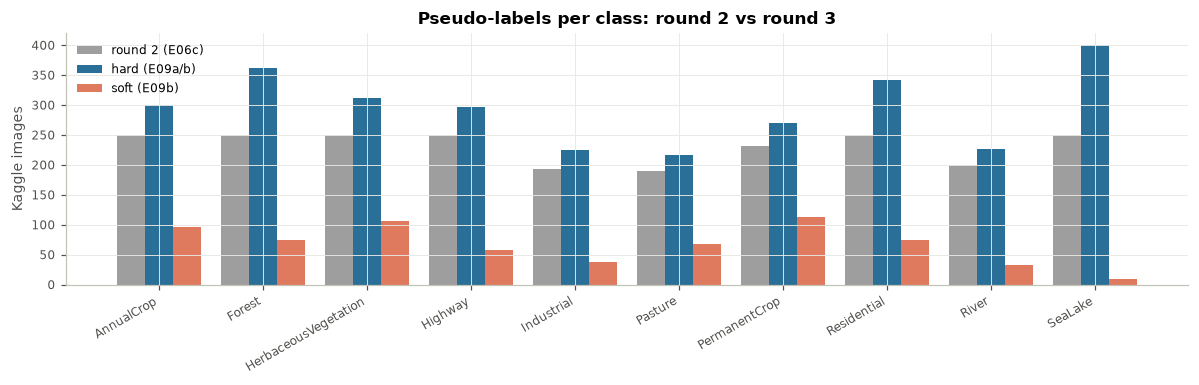

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.6))
x = np.arange(10)
for k, (col, color) in enumerate([("round 2 (E06c)", "#9e9e9e"), ("hard (E09a/b)", "#2a6f97"), ("soft (E09b)", "#e07a5f")]):
    ax.bar(x + (k - 1) * 0.27, selection.loc[CLASSES, col], 0.27, label=col, color=color)
ax.set_xticks(x, CLASSES, rotation=30, ha="right", fontsize=8)
ax.set(ylabel="Kaggle images", title="Pseudo-labels per class: round 2 vs round 3")
ax.legend()
plt.tight_layout()
plt.show()

## 3 · E09a · Hard labels from view agreement

Only the selection differs from E06c: about 2,950 images instead of 2,314, more of every vegetation class, SeaLake
400 instead of 250.

In [4]:
tr_images, tr_labels, _ = add_pseudo_labels(data, table, hard_idx, repeat=REPEAT)
model, normalizer, history, best_state = train_or_load("E09a", tr_images, tr_labels)
results["E09a"] = finish_run(model, normalizer, history, best_state, data, variant="E09a", load_run=LOAD_RUNS["E09a"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config=base_config("E09a", "pl_r3_view_agree_contrast_aug_hist_split_effb0",
                       "hist_split + contrast aug + pseudo-labels round 3 (E06c teacher, 8 views agree), 2x",
                       {"teacher": TEACHER, "selection": "view_agree", "caps": CAPS, "repeat": REPEAT,
                        "n_images": int(len(hard_idx))}))
del tr_images, tr_labels

Pseudo-labelled Kaggle images: 2,948 of 4,232, used 2x (23.8% of the training set, 24,796 images)


epoch  1  train loss 1.493 acc 0.589  val loss 0.308 acc 0.920 *  val_conf 0.834  kg_conf 0.716  kg_sealake 0.241  kg_share_AnnualCrop 0.099  kg_share_Forest 0.156  kg_share_HerbaceousVegetation 0.066  kg_share_Highway 0.085  kg_share_Industrial 0.057  kg_share_Pasture 0.074  kg_share_PermanentCrop 0.081  kg_share_Residential 0.093  kg_share_River 0.047  kg_share_SeaLake 0.241  (65s)


epoch  2  train loss 0.733 acc 0.912  val loss 0.198 acc 0.965 *  val_conf 0.874  kg_conf 0.788  kg_sealake 0.241  kg_share_AnnualCrop 0.089  kg_share_Forest 0.105  kg_share_HerbaceousVegetation 0.099  kg_share_Highway 0.085  kg_share_Industrial 0.068  kg_share_Pasture 0.070  kg_share_PermanentCrop 0.101  kg_share_Residential 0.087  kg_share_River 0.056  kg_share_SeaLake 0.241  (63s)


epoch  3  train loss 0.653 acc 0.942  val loss 0.193 acc 0.965    val_conf 0.884  kg_conf 0.830  kg_sealake 0.244  kg_share_AnnualCrop 0.111  kg_share_Forest 0.132  kg_share_HerbaceousVegetation 0.080  kg_share_Highway 0.079  kg_share_Industrial 0.062  kg_share_Pasture 0.073  kg_share_PermanentCrop 0.076  kg_share_Residential 0.089  kg_share_River 0.055  kg_share_SeaLake 0.244  (63s)


epoch  4  train loss 0.613 acc 0.959  val loss 0.177 acc 0.968 *  val_conf 0.889  kg_conf 0.830  kg_sealake 0.241  kg_share_AnnualCrop 0.128  kg_share_Forest 0.113  kg_share_HerbaceousVegetation 0.101  kg_share_Highway 0.084  kg_share_Industrial 0.051  kg_share_Pasture 0.070  kg_share_PermanentCrop 0.054  kg_share_Residential 0.101  kg_share_River 0.056  kg_share_SeaLake 0.241  (63s)


...

epoch 17  train loss 0.513 acc 0.997  val loss 0.133 acc 0.985    val_conf 0.904  kg_conf 0.883  kg_sealake 0.241  kg_share_AnnualCrop 0.093  kg_share_Forest 0.104  kg_share_HerbaceousVegetation 0.102  kg_share_Highway 0.083  kg_share_Industrial 0.062  kg_share_Pasture 0.072  kg_share_PermanentCrop 0.092  kg_share_Residential 0.091  kg_share_River 0.060  kg_share_SeaLake 0.241  (70s)


epoch 18  train loss 0.510 acc 0.997  val loss 0.132 acc 0.986 *  val_conf 0.904  kg_conf 0.885  kg_sealake 0.241  kg_share_AnnualCrop 0.088  kg_share_Forest 0.107  kg_share_HerbaceousVegetation 0.103  kg_share_Highway 0.083  kg_share_Industrial 0.064  kg_share_Pasture 0.067  kg_share_PermanentCrop 0.097  kg_share_Residential 0.093  kg_share_River 0.059  kg_share_SeaLake 0.241  (70s)


epoch 19  train loss 0.511 acc 0.997  val loss 0.134 acc 0.987 *  val_conf 0.902  kg_conf 0.883  kg_sealake 0.241  kg_share_AnnualCrop 0.089  kg_share_Forest 0.107  kg_share_HerbaceousVegetation 0.102  kg_share_Highway 0.082  kg_share_Industrial 0.062  kg_share_Pasture 0.069  kg_share_PermanentCrop 0.094  kg_share_Residential 0.094  kg_share_River 0.059  kg_share_SeaLake 0.241  (70s)


epoch 20  train loss 0.509 acc 0.998  val loss 0.134 acc 0.986    val_conf 0.902  kg_conf 0.883  kg_sealake 0.241  kg_share_AnnualCrop 0.090  kg_share_Forest 0.109  kg_share_HerbaceousVegetation 0.102  kg_share_Highway 0.082  kg_share_Industrial 0.063  kg_share_Pasture 0.070  kg_share_PermanentCrop 0.090  kg_share_Residential 0.094  kg_share_River 0.059  kg_share_SeaLake 0.241  (71s)


E09a: internal test 98.86% · Kaggle confidence 87.4% (with AdaBN 85.0%) · 4,022,950 parameters
  run folders: runs/2026-10-15_1829_pl_r3_view_agree_contrast_aug_hist_split_effb0, runs/2026-10-15_1830_adabn_balanced_pl_r3_view_agree_contrast_aug_hist_split_effb0


## 4 · E09b · Plus soft labels for the uncertain images

E09a's hard labels plus the images whose views disagree, with the teacher's probabilities (8 views averaged) as target
and loss weight `SOFT_WEIGHT`. EuroSAT images and hard labels become one-hot targets; label smoothing (0.1) applies to
all of them as before.

In [5]:
soft_summary = table.loc[soft_idx].assign(second=np.array(CLASSES)[np.argsort(-teacher_prob[soft_idx], 1)[:, 1]])
print("Most frequent top-2 pairs among the soft-labelled images:")
print(soft_summary.apply(lambda r: " / ".join(sorted([r["pred"], r["second"]])), axis=1).value_counts().head(8).to_string())

tr_images, tr_targets, tr_weights = add_soft_pseudo_labels(data, hard_idx, hard_labels, soft_idx, teacher_prob[soft_idx],
                                                           repeat=REPEAT, soft_weight=SOFT_WEIGHT)
model, normalizer, history, best_state = train_or_load("E09b", tr_images, tr_targets, tr_weights)
results["E09b"] = finish_run(model, normalizer, history, best_state, data, variant="E09b", load_run=LOAD_RUNS["E09b"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config=base_config("E09b", "pl_r3_soft_contrast_aug_hist_split_effb0",
                       "E09a + soft pseudo-labels (teacher probabilities, weight 0.5) for the uncertain images",
                       {"teacher": TEACHER, "selection": "view_agree + soft rest", "caps": CAPS, "repeat": REPEAT,
                        "n_images": int(len(hard_idx)), "n_soft": int(len(soft_idx)), "soft_weight": SOFT_WEIGHT}))
del tr_images, tr_targets, tr_weights

Most frequent top-2 pairs among the soft-labelled images:
AnnualCrop / PermanentCrop              103
Forest / HerbaceousVegetation            90
Pasture / PermanentCrop                  52
Industrial / Residential                 39
HerbaceousVegetation / PermanentCrop     30
AnnualCrop / Pasture                     27
HerbaceousVegetation / Pasture           22
AnnualCrop / Highway                     21


Pseudo-labelled Kaggle images: 2,948 hard + 668 soft (weight 0.5), used 2x (27.7% of the training set, 26,132 images)


epoch  1  train loss 1.496 acc 0.580  val loss 0.344 acc 0.920 *  val_conf 0.810  kg_conf 0.705  kg_sealake 0.239  kg_share_AnnualCrop 0.111  kg_share_Forest 0.143  kg_share_HerbaceousVegetation 0.071  kg_share_Highway 0.082  kg_share_Industrial 0.053  kg_share_Pasture 0.064  kg_share_PermanentCrop 0.091  kg_share_Residential 0.096  kg_share_River 0.050  kg_share_SeaLake 0.239  (76s)


epoch  2  train loss 0.763 acc 0.892  val loss 0.185 acc 0.962 *  val_conf 0.882  kg_conf 0.775  kg_sealake 0.241  kg_share_AnnualCrop 0.086  kg_share_Forest 0.109  kg_share_HerbaceousVegetation 0.100  kg_share_Highway 0.081  kg_share_Industrial 0.065  kg_share_Pasture 0.089  kg_share_PermanentCrop 0.083  kg_share_Residential 0.088  kg_share_River 0.058  kg_share_SeaLake 0.241  (75s)


epoch  3  train loss 0.679 acc 0.925  val loss 0.174 acc 0.968 *  val_conf 0.891  kg_conf 0.822  kg_sealake 0.241  kg_share_AnnualCrop 0.107  kg_share_Forest 0.116  kg_share_HerbaceousVegetation 0.103  kg_share_Highway 0.084  kg_share_Industrial 0.065  kg_share_Pasture 0.062  kg_share_PermanentCrop 0.069  kg_share_Residential 0.099  kg_share_River 0.054  kg_share_SeaLake 0.241  (76s)


...

epoch 17  train loss 0.546 acc 0.985  val loss 0.134 acc 0.984    val_conf 0.902  kg_conf 0.860  kg_sealake 0.242  kg_share_AnnualCrop 0.094  kg_share_Forest 0.103  kg_share_HerbaceousVegetation 0.100  kg_share_Highway 0.079  kg_share_Industrial 0.061  kg_share_Pasture 0.071  kg_share_PermanentCrop 0.091  kg_share_Residential 0.099  kg_share_River 0.061  kg_share_SeaLake 0.242  (77s)


epoch 18  train loss 0.545 acc 0.983  val loss 0.137 acc 0.985    val_conf 0.900  kg_conf 0.857  kg_sealake 0.241  kg_share_AnnualCrop 0.098  kg_share_Forest 0.104  kg_share_HerbaceousVegetation 0.096  kg_share_Highway 0.081  kg_share_Industrial 0.062  kg_share_Pasture 0.072  kg_share_PermanentCrop 0.084  kg_share_Residential 0.099  kg_share_River 0.062  kg_share_SeaLake 0.241  (76s)


epoch 19  train loss 0.544 acc 0.982  val loss 0.135 acc 0.986 *  val_conf 0.901  kg_conf 0.858  kg_sealake 0.241  kg_share_AnnualCrop 0.096  kg_share_Forest 0.103  kg_share_HerbaceousVegetation 0.100  kg_share_Highway 0.083  kg_share_Industrial 0.061  kg_share_Pasture 0.071  kg_share_PermanentCrop 0.083  kg_share_Residential 0.099  kg_share_River 0.062  kg_share_SeaLake 0.241  (77s)


epoch 20  train loss 0.544 acc 0.984  val loss 0.134 acc 0.985    val_conf 0.902  kg_conf 0.859  kg_sealake 0.241  kg_share_AnnualCrop 0.095  kg_share_Forest 0.101  kg_share_HerbaceousVegetation 0.101  kg_share_Highway 0.083  kg_share_Industrial 0.062  kg_share_Pasture 0.071  kg_share_PermanentCrop 0.087  kg_share_Residential 0.095  kg_share_River 0.063  kg_share_SeaLake 0.241  (76s)


E09b: internal test 98.62% · Kaggle confidence 85.4% (with AdaBN 85.0%) · 4,022,950 parameters
  run folders: runs/2026-10-15_1856_pl_r3_soft_contrast_aug_hist_split_effb0, runs/2026-10-15_1856_adabn_balanced_pl_r3_soft_contrast_aug_hist_split_effb0


## 5 · Comparison with the teacher (E06c + AdaBN)

E09 has to beat its teacher. Where do the predictions change: on images the teacher was unsure about (where the errors
are) or on confident ones? And in which classes?

In [6]:
teacher_dir = find_run(TEACHER)
t_model, t_norm, _ = load_run(teacher_dir, device)
teacher_views = predict_views(t_model, data.kg_images, t_norm)
summary = compare_variants(results, reference=teacher_prob, reference_name="E06c")
t_metrics = json.loads((find_run(TEACHER.removeprefix("adabn_balanced_")) / "metrics.json").read_text())
summary.loc["E06c (teacher)"] = {"description": "teacher", "internal test (%)": t_metrics["internal_test_acc"] * 100,
                                 "confidence (%)": teacher_prob.max(1).mean() * 100,
                                 "view agreement (%)": view_agreement(teacher_views) * 100,
                                 "same class as E06c (%)": 100.0, "Kaggle public (%)": kaggle_score(teacher_dir)}
for k, r in results.items():
    changed = r.prob_ada.argmax(1) != teacher_prob.argmax(1)
    summary.loc[k, "changed: teacher unsure (%)"] = changed[table["conf"].values < 0.6].mean() * 100
    summary.loc[k, "changed: teacher confident (%)"] = changed[table["conf"].values >= 0.6].mean() * 100
    summary.loc[k, "changed: soft images (%)"] = changed[soft_idx].mean() * 100
summary.round(2)

,description,internal test (%),confidence (%),view agreement (%),same class as E06c (%),Kaggle public (%),changed: teacher unsure (%),changed: teacher confident (%),changed: soft images (%)
E09a,hist_split + contrast aug + pseudo-labels roun...,98.864198,85.016815,88.657845,95.014178,None,38.58,0.98,31.59
E09b,E09a + soft pseudo-labels (teacher probabiliti...,98.617284,84.959595,91.517013,97.849716,None,18.85,0.16,13.62
E06c (teacher),teacher,98.938272,81.593964,84.215501,100.0,71.502,NaN,NaN,NaN


In [7]:
# Changed predictions: teacher's class (rows) -> new class (columns)
for k, r in results.items():
    new = np.array(CLASSES)[r.prob_ada.argmax(1)]
    changed = new != table["pred"].values
    print(f"{k}: {changed.sum()} images changed ({changed.mean():.1%})")
    display(pd.crosstab(table["pred"].values[changed], new[changed]).rename_axis(index="teacher", columns=k))

E09a: 211 images changed (5.0%)


E09a,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
teacher,,,,,,,,,,
AnnualCrop,0,3,4,1,2,6,12,0,2,0
Forest,2,0,10,0,0,0,1,0,0,0
HerbaceousVegetation,1,19,0,5,1,2,5,5,3,1
Highway,3,1,1,0,3,2,4,2,0,0
Industrial,0,0,2,3,0,2,2,3,0,0
Pasture,1,10,4,2,1,0,13,0,1,0
PermanentCrop,15,5,6,0,4,10,0,0,0,0
Residential,1,2,2,1,5,0,2,0,0,0
River,1,1,3,2,0,0,3,0,0,1


E09b: 91 images changed (2.2%)


E09b,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
teacher,,,,,,,,,,
AnnualCrop,0,0,0,2,0,2,3,0,1,1
Forest,0,0,3,0,0,0,0,0,0,0
HerbaceousVegetation,1,11,0,0,0,3,3,2,0,0
Highway,1,0,2,0,1,1,1,1,4,0
Industrial,0,0,1,0,0,1,0,3,0,0
Pasture,4,3,1,0,1,0,7,0,1,0
PermanentCrop,11,0,1,0,0,3,0,1,1,0
Residential,2,0,1,0,3,0,0,0,1,0
River,1,0,0,0,0,0,0,0,0,1


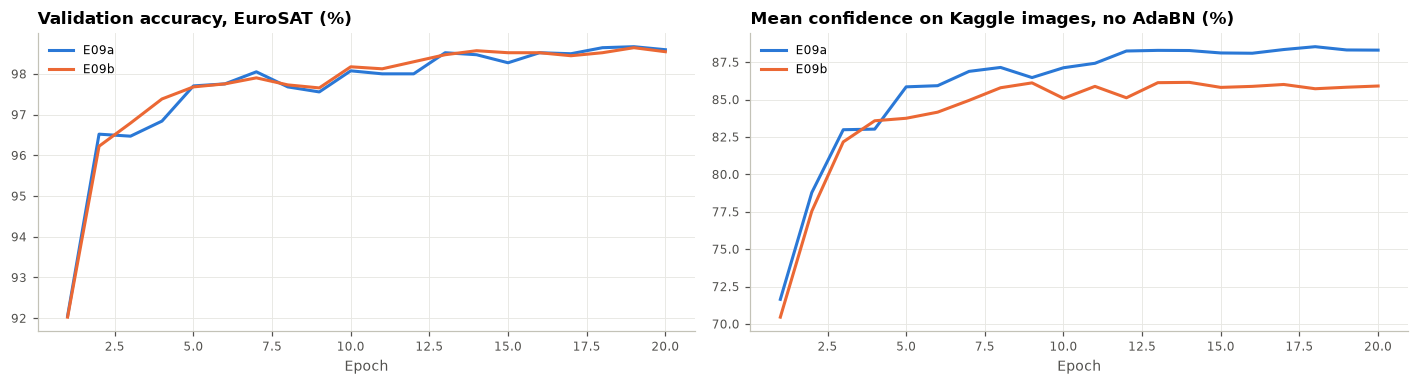

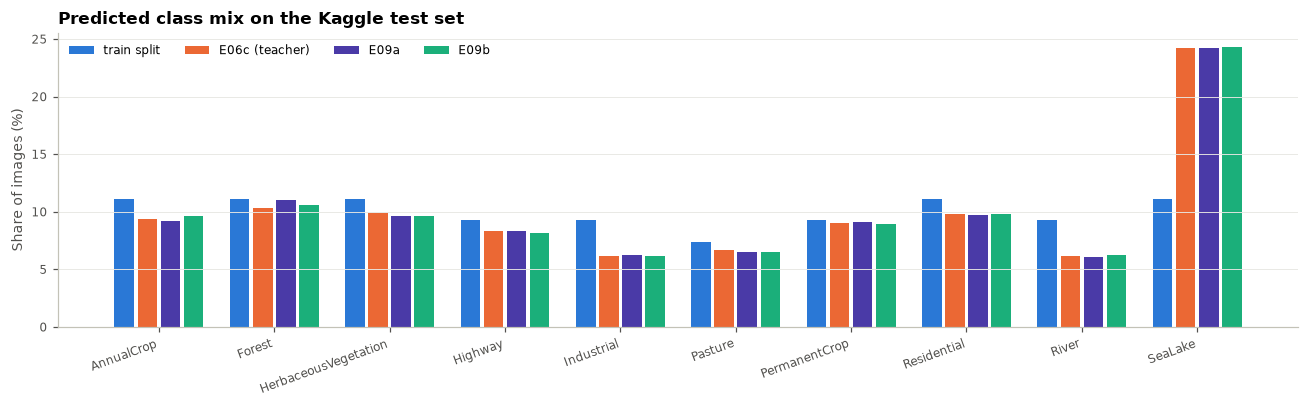

In [8]:
plot_variant_curves(results)
plot_class_mix(pd.DataFrame({"train split": class_mix(np.eye(10)[data.y_tr]), "E06c (teacher)": class_mix(teacher_prob),
                             **{k: class_mix(r.prob_ada) for k, r in results.items()}}))

## 6 · Conclusion

| Model | Pseudo-labels | Internal test | Confidence | View agreement | Same class as E06c | Kaggle public |
|---|---|---|---|---|---|---|
| E06c + AdaBN (teacher) | 2,314 from E06a, 2× | 98.94% | 81.6% | 84.2% | – | 71.50% |
| E09a + AdaBN | 2,948 hard from E06c, 2× | 98.86% | 85.0% | 88.7% | 95.0% | 71.78% |
| **E09a, no AdaBN** (submitted 2026-10-25) | 2,948 hard from E06c, 2× | 98.86% | 87.4% | – | – | **72.67%** |
| E09b + AdaBN | + 668 soft (weight 0.5) | 98.62% | 85.0% | 91.5% | 97.8% | not submitted |

- **View agreement instead of a confidence ranking adds 27% more pseudo-labels** (2,948 vs 2,314), including 20–45%
  more images of every vegetation class; the weakest labels are at 0.55–0.65 confidence instead of down to 0.45.
- **E09a changes the predictions where round 2 did:** 38.6% of the images the teacher was unsure about get a new class,
  only 1.0% of the confident ones (E06a/b/c: 35–38% and 1.3–1.6%). Most changes are within the vegetation and crop
  classes (PermanentCrop ↔ AnnualCrop/Pasture, HerbaceousVegetation ↔ Forest). EuroSAT accuracy is unchanged.
- **Soft labels mostly copy the teacher.** E09b changes only 2.2% of the predictions (E09a 5.0%) and 13.6% of the
  soft-labelled images: training on the teacher's probabilities passes on its uncertainty instead of resolving it. Its
  view agreement is the highest, but that measures stability, not correctness. Internal test drops slightly (98.62%).
- **E09a scores 71.78%, the best so far:** +0.28 over its teacher E06c and +0.09 over the soup E08a (71.69%), as a
  single model trained from a single teacher, so it fits the one-model rule without the soup. The gain is small and
  within public-leaderboard noise, but in the expected direction.

**Next:** round 4 with E09a as teacher, or FixMatch-style consistency training. E09b not submitted.


**Update 2026-10-25:** E09a *without* AdaBN scores 72.67% (+0.89). For its teacher E06c, AdaBN still helps (71.50% with, 71.08% without), so the benefit of AdaBN shrinks as more pseudo-labelled Kaggle images enter training (see E11).